In [1]:
from abacusnbody.data.read_abacus import read_asdf
import numpy as np
import matplotlib.pyplot as plt
#from abacusnbody.analysis.tpcf_corrfunc import calc_power
import os
from astropy.table import vstack
from pycorr.correlation_function import TwoPointCorrelationFunction
import abacusnbody
import blosc as bl
import tools
from astropy.table import Table

In [2]:
'''import sys
print(sys.version)'''

#%pip install --user --no-cache-dir --force-reinstall --no-deps "git+https://github.com/abacusorg/abacusutils@5464e3f90"
#%pip install --user --no-cache-dir blosc2

'import sys\nprint(sys.version)'

In [3]:

#highbase
#mapdir = "/global/cfs/cdirs/desicollab/users/eisenste/AbacusAurora/HighBase_veldir_eps015_AbS/maplogs/col000"
mapdir = "/global/cfs/cdirs/cosmo/staging/AbacusAurora/AbacusAurora_rockV2_c000_ph390_n800/maplogs/"
#read in files
filelist = []
for root, dirs, files in os.walk(mapdir):
    for file in files:
        if "asdf" in file:
            filelist.append(root+"/"+file)

In [4]:
filelist

['/global/cfs/cdirs/cosmo/staging/AbacusAurora/AbacusAurora_rockV2_c000_ph390_n800/maplogs/col000/maplog_z0.00_000_002.asdf',
 '/global/cfs/cdirs/cosmo/staging/AbacusAurora/AbacusAurora_rockV2_c000_ph390_n800/maplogs/col000/maplog_z0.00_000_003.asdf',
 '/global/cfs/cdirs/cosmo/staging/AbacusAurora/AbacusAurora_rockV2_c000_ph390_n800/maplogs/col000/maplog_z0.00_000_001.asdf',
 '/global/cfs/cdirs/cosmo/staging/AbacusAurora/AbacusAurora_rockV2_c000_ph390_n800/maplogs/col000/maplog_z0.00_000_000.asdf',
 '/global/cfs/cdirs/cosmo/staging/AbacusAurora/AbacusAurora_rockV2_c000_ph390_n800/maplogs/col001/maplog_z0.00_001_002.asdf',
 '/global/cfs/cdirs/cosmo/staging/AbacusAurora/AbacusAurora_rockV2_c000_ph390_n800/maplogs/col001/maplog_z0.00_001_001.asdf',
 '/global/cfs/cdirs/cosmo/staging/AbacusAurora/AbacusAurora_rockV2_c000_ph390_n800/maplogs/col001/maplog_z0.00_001_003.asdf',
 '/global/cfs/cdirs/cosmo/staging/AbacusAurora/AbacusAurora_rockV2_c000_ph390_n800/maplogs/col001/maplog_z0.00_001_000

In [6]:
def get_parents(maplogtab,timestep):
    parent_mask = (maplogtab['node_type'] == 3)&(maplogtab['timestep']==timestep)
    parent_indices = np.where(parent_mask)[0]
    return parent_mask, parent_indices

def get_nmergers(maplogtab,parent_indices):
    '''
    Description
        find all the MAPs at a certain timestep and then find the total number of mergers they went through
    Arguments
        maplogtab: Astropy tree of MAPs
        timestep: timestep where you want to find parent MAPs
    Returns:
        List of number of mergers each parent MAP has gone through'''
    #first get a list of all the indices of the parent MAPs you want

    def get_nmerger(index):
        #get length of the branch
        #check which steps in that branch are mergers
        length = maplogtab['length'][index] #get length of this branch
        onetree_nodetype = maplogtab['node_type'][index:index+length] #get node type of everything in branch
        mask = onetree_nodetype == 1 #only choose the merger nodes


        #check if onetree_nodetype[-1] is always formation
        nmergers = np.count_nonzero(mask)
        return nmergers
    
    nmerger_list = [get_nmerger(parent_indices[i]) for i in range(len(parent_indices))]
    return nmerger_list, parent_mask


def largestMergerSize(maplogtab,parent_indices):
    '''
    Description
            takes in a list of head nodes and finds the largest merger for to the main branch for each
    Arguments
        maplogtab: Astropy table of MAPs
        parent_indices: indices of head nodes you're interested in (for example, all the MAPs at a certain timestep)
    Returns
        size of the largest merger to the main branch as a fraction of main branch multiplicity
    '''

    def get_largestmerger(index):
        #get length of the branch
        #check which steps in that branch are mergers
        length = maplogtab['length'][index] #get length of this branch
        onetree_nodetype = maplogtab['node_type'][index:index+length] #get node type of everything in branch
        onetree_mult = maplogtab['mult_sec'][index:index+length]
        mask = onetree_nodetype == 1 #only choose the merger nodes
        if not np.any(mask): return 0
        else:
            largestmerger_ix = np.argmax(onetree_mult[mask])
            largestmerger_mult = onetree_mult[largestmerger_ix]
            return float(largestmerger_mult)/float(maplogtab['mult'][index])
        
    largestmerger_list = [get_largestmerger(parent_indices[i]) for i in range(len(parent_indices))]
    return np.array(largestmerger_list)
    
def getLastNTimeslicesBranch(maplogtab,index,Nslices):
    '''
        returns indices of the last N timeslices along a certain MAP branch
    '''
    branchlength = maplogtab[index]['length']
    timeslices = maplogtab[index:index+branchlength]['node_type'] == 3
    if np.count_nonzero(timeslices) < Nslices: Nslices = np.count_nonzero(timeslices) 
    indices_local = np.where(timeslices)[0]
    return indices_local[:Nslices] + index
        
def integratedRamPressure(maplogtab,parent_indices,nepochs):
    '''
    Description
        takes in a list of head nodes and finds the integrated ram pressure for each
    Arguments
        maplogtab: map log table of timeslices
    '''
        
    def getRamPressure(index, nepochs):      
        #step along the primary branch and get last n epochs of velocity dispersion and 
        indices = getLastNTimeslicesBranch(maplogtab,index,nepochs)
        density = maplogtab['density'][indices]
        rel_vel = maplogtab['rel_vel'][indices]
        return np.sum(density*rel_vel**2)
    rampressure_list = [getRamPressure(parent_indices[i],nepochs) for i in range(len(parent_indices))]
    return np.array(rampressure_list)

In [7]:
def redshiftmask(tab, targetz = 0.225):
    #tab must be a table of redshift slices only
    step2z = tab.meta['Step_to_Z']
    stepindices = np.arange(len(step2z))
    stepmask = [(step in tab['timestep']) for step in stepindices]
    validsteps = stepindices[stepmask]
    step2z = step2z[stepmask]
    idx = np.abs(step2z - 0.225).argmin()
    step = validsteps[idx]
    return (tab['timestep']==step)

def read_select_z(file, targetz = 0.225,load=['pos','mult','node_type','timestep']):
    tab = read_asdf(file, load = load)
    tab = tab[tab['node_type'] == 3]
    tab = tab[redshiftmask(tab,targetz)]
    return tab

def get_z_indices(tab, targetz = 0.225):
    tab = tab[tab['node_type'] == 3]
    indices = np.flatnonzero(redshiftmask(tab,targetz))
    return indices

def compute_history_epoch(file, targetz, functions, arguments, funcnames,load=['pos','mult','node_type','timestep'],
                          colsout=['pos','mult']):
    tab = read_asdf(file, load = load)
    indices = get_z_indices(tab,targetz=targetz)
    epochtab = tab[indices][colsout]
    for i in range(len(functions)):
        function = functions[i]
        args = arguments[i]
        column = function(tab,indices,*args)
        epochtab[funcnames[i]] = column
    return epochtab

In [101]:
functions = [integratedRamPressure]
nepochs = 6
arguments = [[nepochs]]
funcnames = ['pint']
load=['pos','mult','node_type','timestep','length','density','rel_vel']
tab = compute_history_epoch(filelist[0],0.225,functions,arguments,funcnames,load=load)

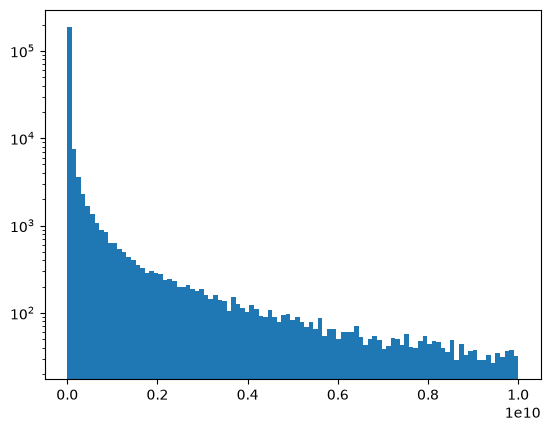

In [108]:
bins = np.linspace(0,1e10,num=100)
plt.hist(tab['pint'],bins=bins)
plt.yscale('log')
plt.xlabel("Integrated Ram Pressure")

In [8]:
tabs = []
for file in filelist:
    tabs.append(read_select_z(file))
tab = vstack(tabs)

In [70]:
test_tab = read_asdf(filelist[0],load=['pos','mult','node_type','timestep','length'])

(array([896264., 454692., 153574.,  60936.,  31867.,  19352.,  13291.,
          9590.,   7364.,   5869.,   4456.,   3800.,   3104.,   2665.,
          2396.,   2076.,   1736.,   1617.,   1487.]),
 array([   0.        ,   52.63157895,  105.26315789,  157.89473684,
         210.52631579,  263.15789474,  315.78947368,  368.42105263,
         421.05263158,  473.68421053,  526.31578947,  578.94736842,
         631.57894737,  684.21052632,  736.84210526,  789.47368421,
         842.10526316,  894.73684211,  947.36842105, 1000.        ]),
 <BarContainer object of 19 artists>)

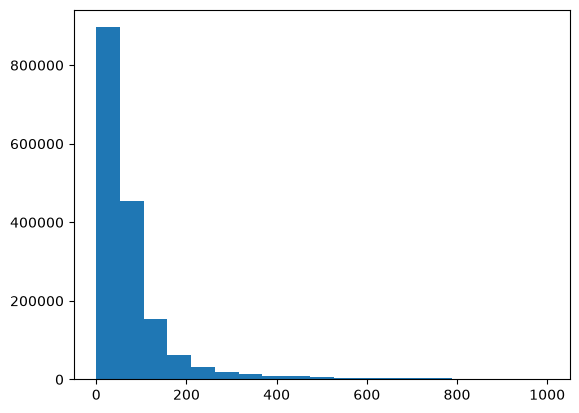

In [34]:
plt.hist(tab['mult'],bins=np.linspace(0,1000,num=20))

In [ ]:
getlast

In [9]:
#Just get a handle on what we're looking at
tab['x'] = tab['pos'][:,0]
tab['y'] = tab['pos'][:,1]
tab['z'] = tab['pos'][:,2]

In [10]:
print(np.min(tab['x']),np.max(tab['x']))
print(np.min(tab['y']),np.max(tab['y']))
print(np.min(tab['z']),np.max(tab['z']))

-108.5 108.5
-108.5 108.5
-108.5 108.5


In [11]:
#Position is returned in Mpc/h (5 kpc/h quantum, fixed); velocity in km/s

In [12]:
boxlength = 2*108.5 #2*102.5 #length in Mpc/h
boxvol = (boxlength)**3 #there are some extra particles at high z?
goaldensity = 0.00247278
numgoal = int(boxvol*goaldensity)
tab.sort('mult')
quant100 = tab[-numgoal:]
print(numgoal)
print("minimum MAP multiplicity",np.min(quant100['mult']))

25267
minimum MAP multiplicity 847


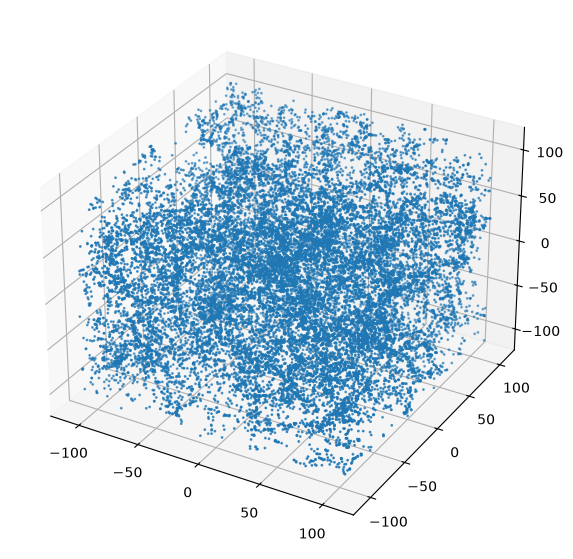

In [31]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')
ax.scatter(quant100['x'],quant100['y'],quant100['z'],s=1)

In [13]:
#make randoms catalog
nrandoms = 200*len(quant100)
rantab = Table()
rantab['x'],rantab['y'],rantab['z'] = (np.random.rand(3,nrandoms)*boxlength - 1/2*boxlength)

(array([505955., 505321., 506007., 505631., 504698., 506161., 504800.,
        504171., 505530., 505126.]),
 array([-1.08499990e+02, -8.67999943e+01, -6.50999984e+01, -4.34000025e+01,
        -2.17000065e+01, -1.06237027e-05,  2.16999853e+01,  4.33999812e+01,
         6.50999771e+01,  8.67999731e+01,  1.08499969e+02]),
 <BarContainer object of 10 artists>)

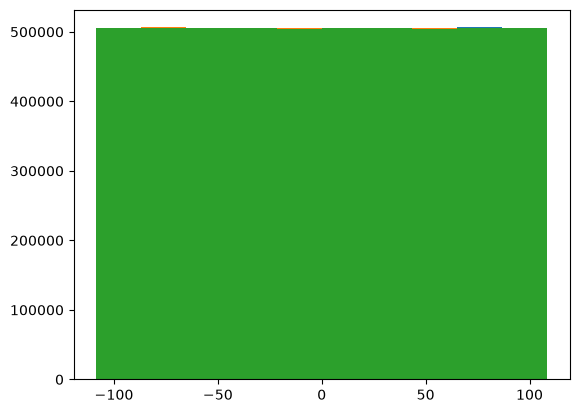

In [14]:
plt.hist(rantab['x'])
plt.hist(rantab['y'])
plt.hist(rantab['z'])

## Calculate correlation function ##

In [20]:
import importlib
import tools
importlib.reload(tools)

<module 'tools' from '/global/u1/c/crmiller/bgsmaps/tools.py'>

In [28]:
'''ndivs = [3,3,3]
lims1D = [-boxlength/2,boxlength/2]
limits = [lims1D for i in range(3)]
boxmasks_data,boxmasks_ran = tools.boxMasks([quant100,rantab],limits,ndivs)

multmasks = tools.makeNDivMasks(quant100, "mult", 100)
D1tab = quant100
D2tab = quant100
D1masks_jack = boxmasks_data
D2masks_jack = boxmasks_data
D2masks_samples = multmasks
stringnames = []
for i in range(100):
    stringnames.append("rockstar_larger_quant"+str(i))'''

ndivs = [3,3,3]
lims1D = [-boxlength/2,boxlength/2]
limits = [lims1D for i in range(3)]
boxmasks_data,boxmasks_ran = tools.boxMasks([quant100,rantab],limits,ndivs)

multmasks = tools.makeNDivMasks(quant100, "mult", 100)
D1tab = quant100
D2tab = quant100
D1masks_jack = boxmasks_data
D2masks_jack = boxmasks_data
D2masks_samples = multmasks
stringname = "rockstar_s10"

In [29]:
#start = np.log10(0.05)
#stop = np.log10(5)
#edges = [np.logspace(start,stop,num=20),[-40,40]]
start = np.log10(0.05)
stop = np.log10(10)
edges = np.logspace(start,stop,num=20)
D2counts = tools.getJackknifeCounts(D1tab, D2tab, D1masks_jack, D2masks_jack, stringname,edges=edges,
                                 position_type='xyz',los='z',mode='s')

In [30]:
stringname = "rockstarxran_s10"
D1tab = quant100
D2tab = rantab
D1masks_jack = boxmasks_data
D2masks_jack = boxmasks_ran
rancounts = tools.getJackknifeCounts(D1tab, D2tab, boxmasks_data, boxmasks_ran, stringname,edges = edges,
                                     position_type='xyz',los='z',mode='s')

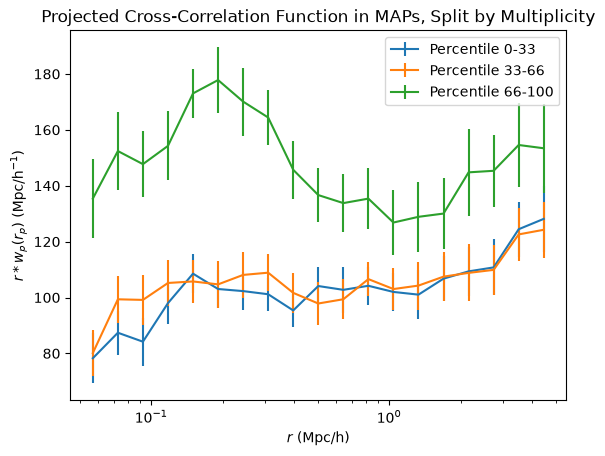

In [58]:
ranges = [[0,33],[33,66],[66,100]]
names = ['Percentile 0-33','Percentile 33-66','Percentile 66-100']
for j in range(len(ranges)):
    D1D2names = []
    for i in np.arange(ranges[j][0],ranges[j][1]):
        D1D2names.append("BGSxquantile_rockstar_multsplit_quant"+str(i))
    D1R1name = "BGSxquantile_rockstarxran"
    rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
    plt.errorbar(rcenters,DavisPeeblesEstimators,label=names[j],yerr = jackerror)

#plt.xscale('log')#, yerr = jackerror)
plt.ylabel(r"$r*w_p(r_p)$ (Mpc/h$^{-1}$)")
plt.xlabel("$r$ (Mpc/h)")
plt.title("Projected Cross-Correlation Function in MAPs, Split by Multiplicity")
plt.legend()
plt.xscale('log')

## old stuff below ##

In [116]:
DavisPeeblesEstimators

array([-118.58124571, -192.93709316,  639.92959378,           nan,
                 nan,           nan,           nan,           nan,
                 nan,           nan,           nan,           nan,
                 nan])

In [19]:
#calculate the correlation function

sbins = np.logspace(-2,2,num=20)
cart_pos = np.array([maps_z0_2['x'],maps_z0_2['y'],maps_z0_2['z']])
tpcf_all = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_all.save("correlationfunction/tpcf_all")

In [25]:
cart_pos = np.array([highmult['x'],highmult['y'],highmult['z']])
tpcf_highmult = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_highmult.save("correlationfunction/tpcf_highmult")

In [42]:
mult_70 = maps_z0_2[maps_z0_2['mult'] > 70]
cart_pos = np.array([mult_70['x'],mult_70['y'],mult_70['z']])
tpcf_70 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_70.save("correlationfunction/tpcf_mult70")

In [36]:
binsmed = (sbins[:-1]+ sbins[1:])/2

In [43]:
allcorr = tpcf_all.get_corr()*binsmed**2
highmultcorr = tpcf_highmult.get_corr()*binsmed**2
corr70 = tpcf_70.get_corr()*binsmed**2

Text(0.5, 1.0, 'MAP Clustering for Several Multiplicities')

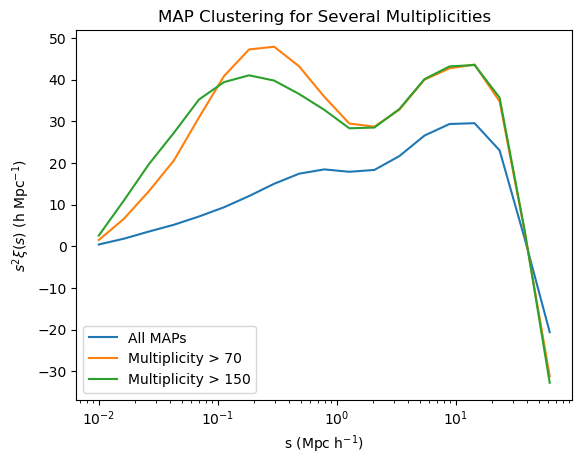

In [44]:
plt.figure()
plt.plot(sbins[:-1],allcorr,label='All MAPs')
plt.plot(sbins[:-1],corr70,label='Multiplicity > 70')
plt.plot(sbins[:-1],highmultcorr,label='Multiplicity > 150')
plt.legend()
plt.xlabel(r"s (Mpc h$^{-1}$)")
plt.xscale('log')
plt.ylabel(r"$s^2\xi(s)$ (h Mpc$^{-1}$)")
plt.title("MAP Clustering for Several Multiplicities")


In [ ]:
def get_parents(maplogtab,timestep):
    parent_mask = (maplogtab['node_type'] == 3)&(maplogtab['timestep']==timestep)
    parent_indices = np.where(parent_mask)[0]
    return parent_mask, parent_indices

def get_nmergers(maplogtab,parent_indices):
    '''
    Description
        find all the MAPs at a certain timestep and then find the total number of mergers they went through
    Arguments
        maplogtab: Astropy tree of MAPs
        timestep: timestep where you want to find parent MAPs
    Returns:
        List of number of mergers each parent MAP has gone through'''
    #first get a list of all the indices of the parent MAPs you want

    def get_nmerger(index):
        #get length of the branch
        #check which steps in that branch are mergers
        length = maplogtab['length'][index] #get length of this branch
        onetree_nodetype = maplogtab['node_type'][index:index+length] #get node type of everything in branch
        mask = onetree_nodetype == 1 #only choose the merger nodes


        #check if onetree_nodetype[-1] is always formation
        nmergers = np.count_nonzero(mask)
        return nmergers
    
    nmerger_list = [get_nmerger(parent_indices[i]) for i in range(len(parent_indices))]
    return nmerger_list, parent_mask


def largestMergerSize(maplogtab,parent_indices):
    '''
    Description
            takes in a list of head nodes and finds the largest merger for to the main branch for each
    Arguments
        maplogtab: Astropy table of MAPs
        parent_indices: indices of head nodes you're interested in (for example, all the MAPs at a certain timestep)
    Returns
        size of the largest merger to the main branch as a fraction of main branch multiplicity
    '''

    def get_largestmerger(index):
        #get length of the branch
        #check which steps in that branch are mergers
        length = maplogtab['length'][index] #get length of this branch
        onetree_nodetype = maplogtab['node_type'][index:index+length] #get node type of everything in branch
        onetree_mult = maplogtab['mult_sec'][index:index+length]
        mask = onetree_nodetype == 1 #only choose the merger nodes
        if not np.any(mask): return 0
        else:
            largestmerger_ix = np.argmax(onetree_mult[mask])
            largestmerger_mult = onetree_mult[largestmerger_ix]
            return float(largestmerger_mult)/float(maplogtab['mult'][index])
        
    largestmerger_list = [get_largestmerger(parent_indices[i]) for i in range(len(parent_indices))]
    return np.array(largestmerger_list)

def integratedRamPressure(maplogtab,parent_indices,nepochs):
    '''
    Description
        takes in a list of head nodes and finds the integrated ram pressure for each
    Arguments
        maplogtab: map log table of timeslices ONLY
    '''
    def getRamPressure(index, nepochs):      
        #step along the primary branch and get last n epochs of velocity dispersion and 
        lengths = maplogtab['length'][index:index + nepochs]
        if 0 in lengths:
            nepochs = np.argmax(lengths == 0) + 1 #make sure you haven't started to go down another branch
            #that would be a total edge case since these MAPs with a high multiplicity floor should not have formed recently
        density = maplogtab['density'][index:index + nepochs]
        rel_vel = maplogtab['rel_vel'][index:index + nepochs]
        return np.sum(density*rel_vel**2)
    rampressure_list = [getRamPressure(parent_indices[i]) for i in range(len(parent_indices))]
    return np.array(rampressure_list)

In [173]:
parent_indices = np.where(z_0p2_mask)[0]
largestmerger_z0p2 = largestMergerSize(tab,parent_indices)

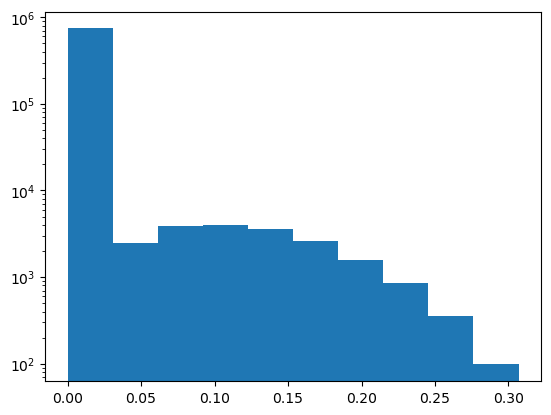

In [166]:
plt.hist(largestmerger_z0p2)
plt.yscale('log')

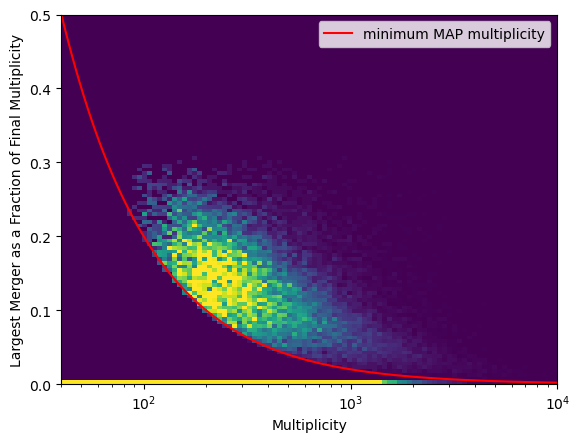

In [240]:
plt.hist2d(maps_z0_2['mult'],largestmerger_z0p2,bins=(np.logspace(np.log10(40),4,num=100),np.linspace(0,0.5,num=100)),density=True,vmax=7e-4)
plt.xlabel("Multiplicity")
plt.ylabel("Largest Merger as a Fraction of Final Multiplicity")
plt.xscale('log')

mults = np.logspace(0,4,num=200)
plt.plot(mults,20/mults,label='minimum MAP multiplicity',color='red')
plt.legend()
#plt.yscale('log')

Text(0.5, 1.0, 'MAP Mergers for Several Final Multiplicities')

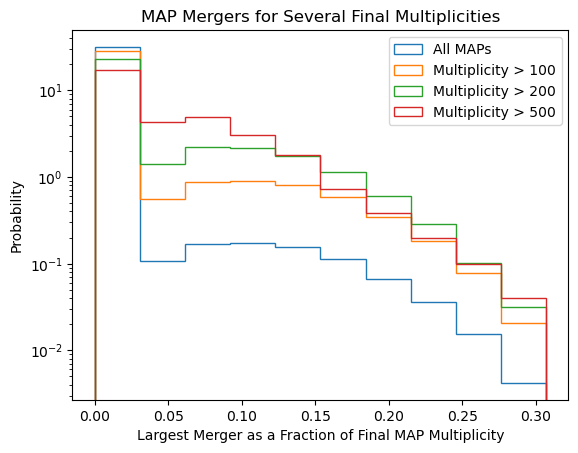

In [179]:
mask_200 = maps_z0_2['mult'] > 200
mask_100 = maps_z0_2['mult'] > 100
mask_500 = maps_z0_2['mult'] > 500

plt.hist(largestmerger_z0p2,label="All MAPs",histtype='step',density=True)
plt.hist(largestmerger_z0p2[mask_100],label = "Multiplicity > 100",density=True,histtype='step')
plt.hist(largestmerger_z0p2[mask_200],label = "Multiplicity > 200",density=True,histtype='step')
plt.hist(largestmerger_z0p2[mask_500],label = "Multiplicity > 500",density=True,histtype='step')
plt.legend()
plt.xlabel("Largest Merger as a Fraction of Final MAP Multiplicity")
plt.ylabel("Probability")
plt.yscale('log')

plt.title("MAP Mergers for Several Final Multiplicities")

In [201]:
bigmerg_0p1 = maps_z0_2[(largestmerger_z0p2 > 0.1)&(maps_z0_2['mult'] > 100)]
cart_pos = np.array([bigmerg_0p1['x'],bigmerg_0p1['y'],bigmerg_0p1['z']])
tpcf_bigmerg_0p1 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_bigmerg_0p1.save("correlationfunction/tpcf_bigmerg_0p1")

bigmerg_0p2 = maps_z0_2[(largestmerger_z0p2 > 0.2)&(maps_z0_2['mult'] > 100)]
cart_pos = np.array([bigmerg_0p2['x'],bigmerg_0p2['y'],bigmerg_0p2['z']])
tpcf_bigmerg_0p2 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_bigmerg_0p2.save("correlationfunction/tpcf_bigmerg_0p2")

all_multlim = maps_z0_2[(maps_z0_2['mult'] > 100)]
cart_pos = np.array([all_multlim['x'],all_multlim['y'],all_multlim['z']])
tpcf_all_multlim = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_all_multlim.save("correlationfunction/tpcf_all_multlim")

In [202]:
corr_all_multlim = tpcf_all_multlim.get_corr()*binsmed**2
corr_bigmerg_0p2 = tpcf_bigmerg_0p2.get_corr()*binsmed**2
corr_bigmerg_0p1 = tpcf_bigmerg_0p1.get_corr()*binsmed**2

Text(0.5, 1.0, 'MAP Clustering for Different Merger Histories \n (MAP Multiplicity > 100)')

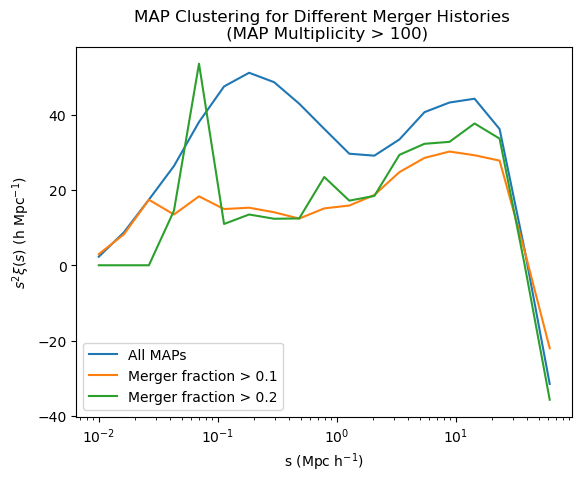

In [203]:
plt.figure()
plt.plot(sbins[:-1],corr_all_multlim,label='All MAPs')
plt.plot(sbins[:-1],corr_bigmerg_0p1,label='Merger fraction > 0.1')
plt.plot(sbins[:-1],corr_bigmerg_0p2,label='Merger fraction > 0.2')
plt.legend()
plt.xlabel(r"s (Mpc h$^{-1}$)")
plt.xscale('log')
plt.ylabel(r"$s^2\xi(s)$ (h Mpc$^{-1}$)")
plt.title("MAP Clustering for Different Merger Histories \n (MAP Multiplicity > 100)")

Text(0, 0.5, 'MAPs')

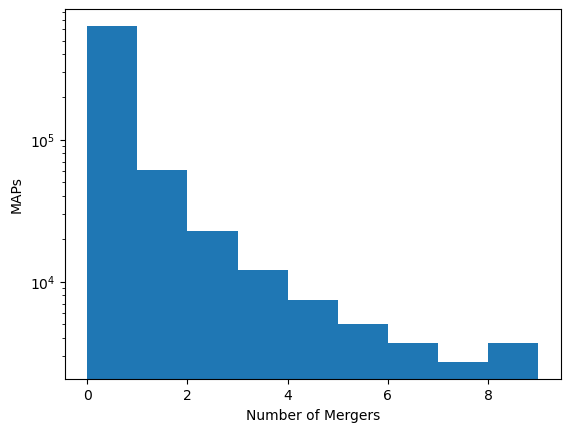

In [113]:
plt.hist(nmergers_z0_2,bins=np.arange(10))
plt.yscale('log')
plt.xlabel("Number of Mergers")
plt.ylabel("MAPs")

'plt.yscale("log")\nplt.xscale("log")'

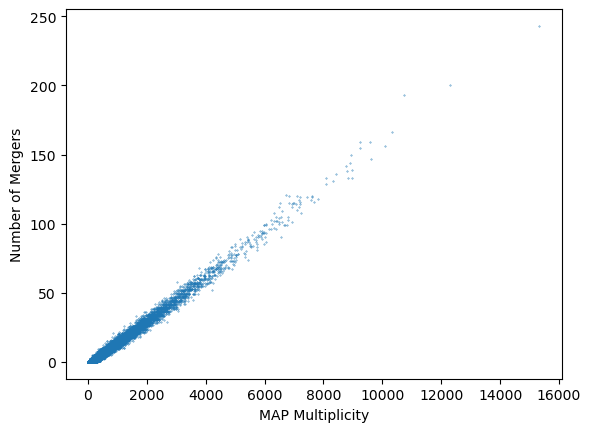

In [122]:
plt.scatter(maps_z0_2['mult'],nmergers_z0_2,s=0.1)
plt.xlabel("MAP Multiplicity")
plt.ylabel("Number of Mergers")
'''plt.yscale("log")
plt.xscale("log")'''

In [115]:
disrupted = maps_z0_2[np.array(nmergers_z0_2) > 1]

In [116]:
cart_pos = np.array([disrupted['x'],disrupted['y'],disrupted['z']])
tpcf_disrupted = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_disrupted.save("correlationfunction/tpcf_disrupted")

In [117]:
disrupted_0 = maps_z0_2[np.array(nmergers_z0_2) > 0]
cart_pos = np.array([disrupted_0['x'],disrupted_0['y'],disrupted_0['z']])
tpcf_disrupted0 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_disrupted0.save("correlationfunction/tpcf_disrupted0")

In [118]:
disrupted_3 = maps_z0_2[np.array(nmergers_z0_2) > 3]
cart_pos = np.array([disrupted_3['x'],disrupted_3['y'],disrupted_3['z']])
tpcf_disrupted3 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_disrupted3.save("correlationfunction/tpcf_disrupted3")

In [119]:
disrupted_5 = maps_z0_2[np.array(nmergers_z0_2) > 5]
cart_pos = np.array([disrupted_5['x'],disrupted_5['y'],disrupted_5['z']])
tpcf_disrupted5 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_disrupted5.save("correlationfunction/tpcf_disrupted5")

In [120]:
corrdisrupted = tpcf_disrupted.get_corr()*binsmed**2
corrdisrupted0 = tpcf_disrupted0.get_corr()*binsmed**2
corrdisrupted3 = tpcf_disrupted3.get_corr()*binsmed**2
corrdisrupted5 = tpcf_disrupted5.get_corr()*binsmed**2

Text(0.5, 1.0, 'MAP Clustering for Different Merger Histories')

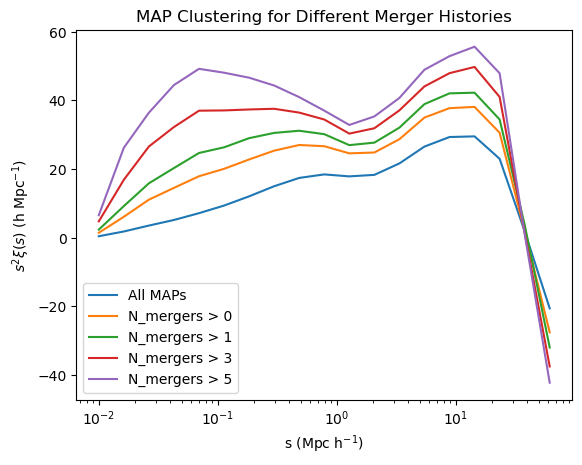

In [121]:
plt.figure()
plt.plot(sbins[:-1],allcorr,label='All MAPs')
plt.plot(sbins[:-1],corrdisrupted0,label='N_mergers > 0')
plt.plot(sbins[:-1],corrdisrupted,label='N_mergers > 1')
plt.plot(sbins[:-1],corrdisrupted3,label='N_mergers > 3')
plt.plot(sbins[:-1],corrdisrupted5,label='N_mergers > 5')
plt.legend()
plt.xlabel(r"s (Mpc h$^{-1}$)")
plt.xscale('log')
plt.ylabel(r"$s^2\xi(s)$ (h Mpc$^{-1}$)")
plt.title("MAP Clustering for Different Merger Histories")

Text(0.5, 1.0, 'MAP Multiplicity for Different Merger Histories')

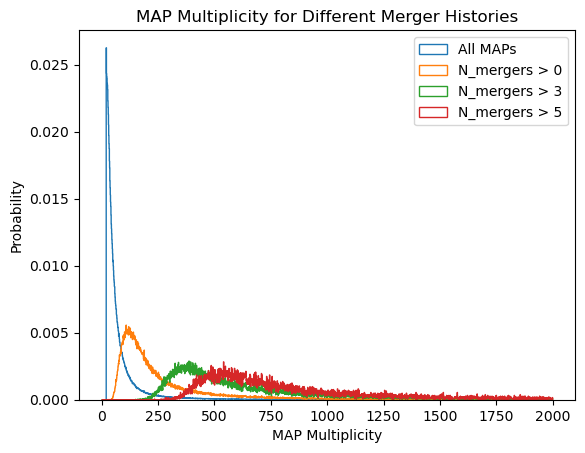

In [124]:
plt.hist(maps_z0_2['mult'],bins=np.arange(0,2000),density=True,label="All MAPs",histtype='step')
plt.hist(disrupted_0['mult'],bins=np.arange(0,2000),density=True,histtype='step',label = "N_mergers > 0")
#plt.hist(disrupted['mult'],bins=np.arange(0,200),density=True,histtype='step',label = "N_mergers > 1")
plt.hist(disrupted_3['mult'],bins=np.arange(0,2000),density=True,histtype='step',label = "N_mergers > 3")
plt.hist(disrupted_5['mult'],bins=np.arange(0,2000),density=True,histtype='step',label = "N_mergers > 5")
plt.legend()
plt.xlabel("MAP Multiplicity")
plt.ylabel("Probability")
plt.title("MAP Multiplicity for Different Merger Histories")

In [125]:
maps_z0_2['nmerg/mult'] = nmergers_z0_2/maps_z0_2['mult']

Text(0, 0.5, 'Number of MAPs')

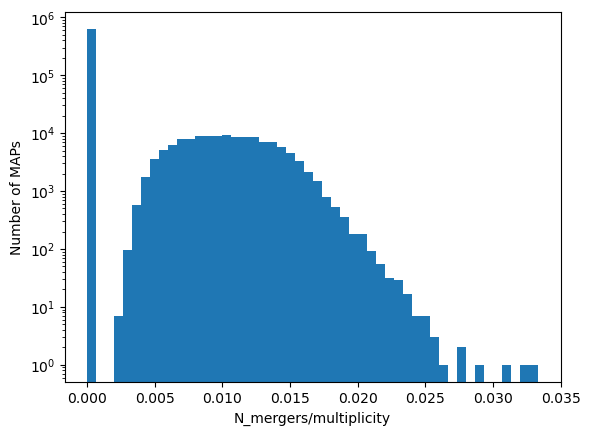

In [138]:
plt.hist(maps_z0_2['nmerg/mult'],bins=50)
plt.yscale('log')
plt.xlabel("N_mergers/multiplicity")
plt.ylabel("Number of MAPs")

In [129]:
mergmult_0p01 = maps_z0_2[maps_z0_2['nmerg/mult'] > 0.01]
cart_pos = np.array([mergmult_0p01['x'],mergmult_0p01['y'],mergmult_0p01['z']])
tpcf_mergmult_0p01 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_mergmult_0p01.save("correlationfunction/tpcf_mergmult_0p01")

In [134]:
mergmult_0p015 = maps_z0_2[maps_z0_2['nmerg/mult'] > 0.015]
cart_pos = np.array([mergmult_0p015['x'],mergmult_0p015['y'],mergmult_0p015['z']])
tpcf_mergmult_0p015 = TwoPointCorrelationFunction("s",sbins,cart_pos,boxsize=2*102.5)
tpcf_mergmult_0p015.save("correlationfunction/tpcf_mergmult_0p015")

In [136]:
corrmergmult_0p015 = tpcf_mergmult_0p015.get_corr()*binsmed**2
corrmergmult_0p01 = tpcf_mergmult_0p01.get_corr()*binsmed**2

Text(0.5, 1.0, 'MAP Clustering for Different Merger Histories')

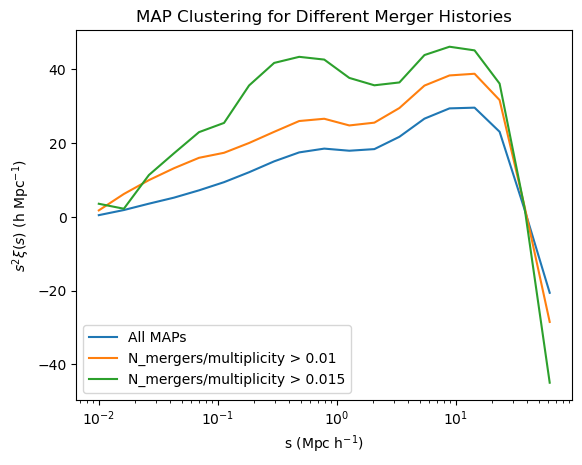

In [137]:
plt.figure()
plt.plot(sbins[:-1],allcorr,label='All MAPs')
plt.plot(sbins[:-1],corrmergmult_0p01,label='N_mergers/multiplicity > 0.01')
plt.plot(sbins[:-1],corrmergmult_0p015,label='N_mergers/multiplicity > 0.015')
plt.legend()
plt.xlabel(r"s (Mpc h$^{-1}$)")
plt.xscale('log')
plt.ylabel(r"$s^2\xi(s)$ (h Mpc$^{-1}$)")
plt.title("MAP Clustering for Different Merger Histories")